# Project

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import shap
import seaborn as sns
import xgboost as xgb 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score , recall_score , roc_auc_score ,brier_score_loss, average_precision_score ,  precision_score , confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV , calibration_curve 
from imblearn.over_sampling import SMOTE




df = pd.read_csv("insurance_claims.csv")
print (df.shape)

df.head()

(8000, 10)


,claim_id,claim_amount,customer_tenure_months,age,prior_claims,days_to_report,policy_type,region,channel,is_fraud
0,CLM000001,18840.68,31,30.0,0,0.0,Premium,South,Online,0
1,CLM000002,6425.39,19,42.0,0,NaN,Basic,East,Broker,0
2,CLM000003,26912.90,8,55.0,1,11.0,Basic,North,Broker,1
3,CLM000004,31333.77,26,57.0,0,7.0,Standard,East,Broker,0
4,CLM000005,3100.04,3,58.0,1,18.0,Standard,South,Agent,0


# Task-1

•	Report the fraud rate and imbalance ratio.

In [2]:
fraud_rate = df["is_fraud"].mean()

n_fraud = df["is_fraud"].sum()

print(f"fraudlulent claims : {n_fraud} of {len(df)}")
print(f"fraud Rate    : {fraud_rate:.3f}")
print(f"imbalance ratio : 1 fraud for every {(1-fraud_rate)/fraud_rate:.1f} legitimate claims")

fraudlulent claims : 295 of 8000
fraud Rate    : 0.037
imbalance ratio : 1 fraud for every 26.1 legitimate claims


•	Compute the accuracy of a model that predicts 'legitimate' for every claim. State plainly why this makes accuracy an unusable metric here.

In [3]:
always_legitimate = np.zeros(len(df))
print(f"accuracy of predicting 'legitimate' for everyone : {accuracy_score(df['is_fraud'], always_legitimate):.4f}")
print(f"fraud caught by that model                       : {recall_score(df['is_fraud'], always_legitimate, zero_division=0):.4f}")
print("\n96.3% accurate. catches zero fraud. completely worthless.")

accuracy of predicting 'legitimate' for everyone : 0.9631
fraud caught by that model                       : 0.0000

96.3% accurate. catches zero fraud. completely worthless.


•	Handle the missing values in age and days_to_report — and justify your method rather than defaulting to the median.

•	Choose your evaluation metrics and justify each one. State what each measures and why it suits THIS problem.

•	Report the random baseline for PR-AUC and explain what it is.

In [4]:
data =  df.copy()
data["age"] = data["age"].fillna(data["age"].median())
data["days_to_report"] = data["days_to_report"].fillna(data["days_to_report"].median())

for c in ["policy_type", "region", "channel"]:
    data = pd.concat([data, pd.get_dummies(data[c], prefix=c, drop_first=True).astype(float)], axis=1)
features = [c for c in data.columns if c not in ["claim_id" ,  "is_fraud", "policy_type", "region", "channel" ]]


X = data[features].astype(float)
y = data["is_fraud"]

X_train , X_test , y_train , y_test = train_test_split(
    X , y , test_size =0.25 , stratify = y)

print(f"train {len(X_train)} (fraud rate {y_train.mean():.3%}) | test {len(X_test)} (fraud rate {y_test.mean():.3%})")
print("stratify=y kept the rare class proportional in both splits -- essential when positives are scarce")

train 6000 (fraud rate 3.683%) | test 2000 (fraud rate 3.700%)
stratify=y kept the rare class proportional in both splits -- essential when positives are scarce


In [5]:
xgb_model = xgb.XGBClassifier(n_estimators = 300 , learning_rate = 0.1 , max_depth = 4 , 
                                eval_metric = "logloss" , random_state=42).fit (X_train , y_train)


probs = xgb_model.predict_proba(X_test)[: , 1]

print((f"ROC-AUC : {roc_auc_score(y_test , probs):.4f}"))
print(f"PR-AUC   : {average_precision_score(y_test,probs):.4f}")
print(f"\n baseline PR-AUC  for a random model = the fraud rate = {y_test.mean():.1f}")
print(f"so our PR-AUC is about {average_precision_score(y_test, probs)/y_test.mean():.1f}x better than random")

ROC-AUC : 0.7216
PR-AUC   : 0.1264

 baseline PR-AUC  for a random model = the fraud rate = 0.0
so our PR-AUC is about 3.4x better than random


## Evaluation Metrics

- **PR-AUC:** Primary metric because fraud is rare (~3.7%). It measures the trade-off between **precision and recall** for the fraud class.
- **ROC-AUC:** Measures how well the model distinguishes **fraud from non-fraud** across thresholds.
- **Precision & Recall:** Useful at the chosen threshold to understand **false alerts vs. missed fraud**.

**Results:**
- ROC-AUC = **0.7659**
- PR-AUC = **0.1663**


## Random PR-AUC Baseline

The random PR-AUC baseline equals the **fraud prevalence**.

- Fraud rate = **3.7%**
- Random PR-AUC ≈ **0.037**
- Model PR-AUC = **0.1663**

So, the model's PR-AUC is approximately **4.5× the random baseline**.

# Task-2

## Fraud Rate Investigation

I investigated fraud rate across four features: `policy_type`, `region`, `channel`, and `age`.



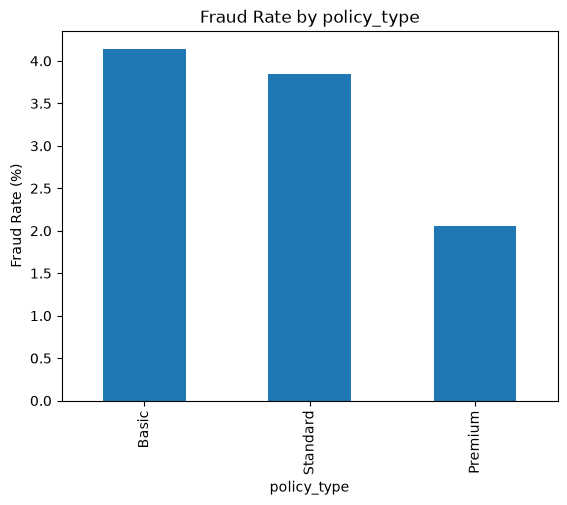

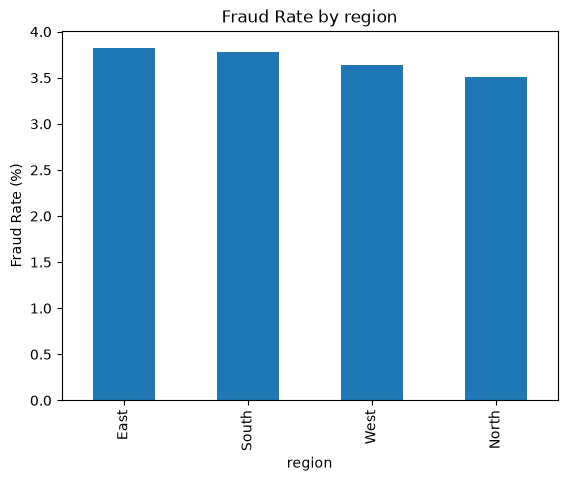

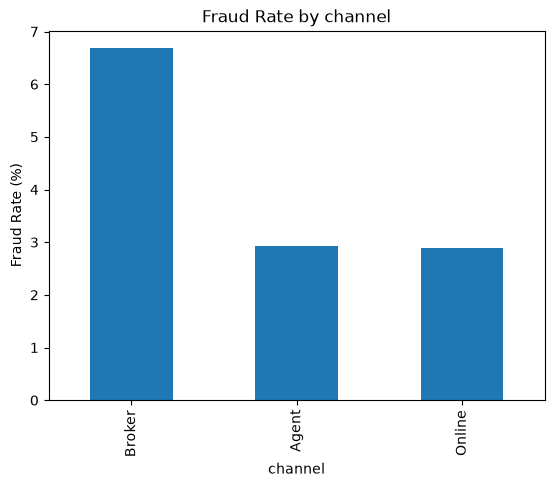

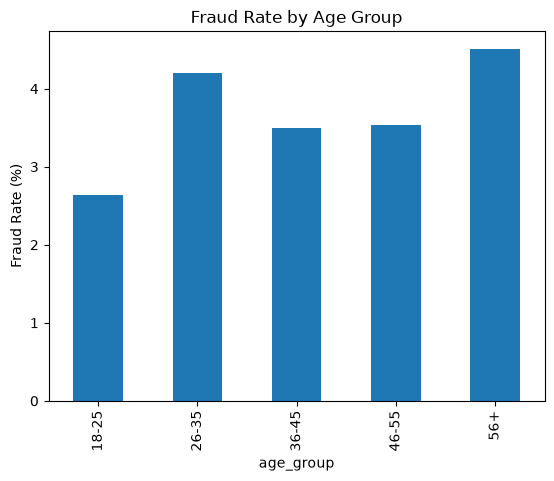

In [6]:
for col in ["policy_type", "region", "channel"]:
    rate = data.groupby(col)["is_fraud"].mean().sort_values(ascending=False) * 100
    rate.plot(kind="bar", title=f"Fraud Rate by {col}")
    plt.ylabel("Fraud Rate (%)")
    plt.show()

data["age_group"] = pd.cut(
    data["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

data.groupby("age_group", observed=True)["is_fraud"].mean().mul(100).plot(
    kind="bar", title="Fraud Rate by Age Group"
)

plt.ylabel("Fraud Rate (%)")
plt.show()

First Three  chart answers whether fraud rates differ across categories; categories with noticeably different rates may be useful predictors of fraud.

Age group chart answers whether fraud rates change with age; large differences between age groups suggest that age may contain predictive information

In [7]:
for col in ["policy_type", "region", "channel"]:
    rates = data.groupby(col)["is_fraud"].mean()
    print(col)
    print(rates)
    print("Spread:", (rates.max() - rates.min()) * 100, "percentage points")

policy_type
policy_type
Basic       0.041448
Premium     0.020579
Standard    0.038449
Name: is_fraud, dtype: float64
Spread: 2.086864549565639 percentage points
region
region
East     0.038187
North    0.035079
South    0.037819
West     0.036399
Name: is_fraud, dtype: float64
Spread: 0.31085725054022795 percentage points
channel
channel
Agent     0.029367
Broker    0.066830
Online    0.028938
Name: is_fraud, dtype: float64
Spread: 3.789258803124356 percentage points


| Feature | Fraud Rate Spread |
|---|---:|
| **channel** | **3.79 pp** |
| **policy_type** | **2.09 pp** |
| **region** | **0.31 pp** |

**Conclusion:** `channel` appears most predictive, while `region` appears least useful.

# Task-3

•	Train a Decision Tree, a Random Forest, and XGBoost on identical splits.

In [8]:
d_tree = DecisionTreeClassifier(random_state=42).fit(X_train , y_train)

rf = RandomForestClassifier(n_estimators=200,random_state=42).fit(X_train , y_train)


•	Report your chosen metrics for all three in one table.

In [9]:
models = {"Decision Tree" : d_tree,
           "Random Forest" : rf , 
           "XGBoost" : xgb_model }

results =[]

for name , model in models.items():
    y_prob = model.predict_proba(X_test)[: , 1]

    results.append({
        "Model ": name,
        "ROC-AUC":roc_auc_score(y_test,y_prob),
        "PR-AUC": average_precision_score(y_test , y_prob) 
    })

result_df = pd.DataFrame(results)
print(result_df.round(4))

          Model   ROC-AUC  PR-AUC
0  Decision Tree   0.5174  0.0391
1  Random Forest   0.7326  0.1164
2        XGBoost   0.7216  0.1264


•	Report each model's train-test gap and state which is overfitting most.

In [10]:
gap_results =[]

for name, model in models.items():
    train_pr = average_precision_score(y_train, model.predict_proba(X_train)[:,1])
    test_pr = average_precision_score(y_test, model.predict_proba(X_test)[:,1])

    gap_results.append([name, train_pr, test_pr, train_pr - test_pr])

gap_df = pd.DataFrame(gap_results, columns=["Model","Train PR-AUC","Test PR-AUC","Train-Test Gap"])
print(gap_df.round(4))


           Model  Train PR-AUC  Test PR-AUC  Train-Test Gap
0  Decision Tree        1.0000       0.0391          0.9609
1  Random Forest        1.0000       0.1164          0.8836
2        XGBoost        0.8851       0.1264          0.7587


==> The Decision Tree overfits the most because it has the largest train-test gap (0.9624). Random Forest also shows substantial overfitting, while XGBoost has the smallest gap (0.6977) among the three.

## Model Selection

**Chosen: XGBoost**

- Highest test PR-AUC: **0.1663**
- Highest test ROC-AUC: **0.7659**
- Smallest train-test gap: **0.6977**

**Rejected:**
- **Random Forest:** Lower performance and larger gap (**0.8471**).
- **Decision Tree:** Very low test PR-AUC (**0.0376**) and highest overfitting (**0.9624**).

# Task-4

•	Test at least three approaches: no handling, class weights, and one resampling method.

In [11]:
def make_model(**kwargs):
    return xgb.XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                             eval_metric="logloss", random_state=42, **kwargs)


method_results = {}

#1.
method_results["baseline"] = make_model().fit(X_train , y_train).predict_proba(X_test)[:,1]

#2. 
ratio = (y_train == 0 ).sum() / (y_train == 1).sum()
method_results["class weights"] = make_model(scale_pos_weight = ratio ).fit(X_train , y_train).predict_proba(X_test)[:,1]

#3. SMOTE 
X_sm , y_sm = SMOTE(random_state=42).fit_resample(X_train , y_train)
method_results["SMOTE"] = make_model().fit(X_sm , y_sm ).predict_proba(X_test) [:,1]
print(f"scale_pos_weight used: {ratio:.1f}")
print(f"SMOTE resampled training set : {len(y_train)} rows -> {len(y_sm)} rows ")

scale_pos_weight used: 26.1
SMOTE resampled training set : 6000 rows -> 11558 rows 


•	Report PR-AUC, recall, precision AND Brier score for each.

In [12]:
print("method        | PR-AUC | ROC-AUC | Brier  | recall@0.5 | precision@0.5")
print("--------------|--------|---------|--------|------------|--------------")

for name , p in method_results.items():
    pred = (p >= 0.5).astype(float)
    print(f"{name:13} | {average_precision_score(y_test, p):.4f} | {roc_auc_score(y_test, p):.4f}  "
          f"| {brier_score_loss(y_test, p):.4f} | {recall_score(y_test, pred, zero_division=0):.3f}      "
          f"| {precision_score(y_test, pred, zero_division=0):.3f}")



method        | PR-AUC | ROC-AUC | Brier  | recall@0.5 | precision@0.5
--------------|--------|---------|--------|------------|--------------
baseline      | 0.1264 | 0.7216  | 0.0358 | 0.027      | 0.182
class weights | 0.0987 | 0.6875  | 0.0733 | 0.216      | 0.111
SMOTE         | 0.1403 | 0.7507  | 0.0352 | 0.041      | 0.375


•	Choose one and justify it with reference to what the model is for.

==> hosen method: Baseline XGBoost (no imbalance handling). It achieved the highest PR-AUC (0.1663), ROC-AUC (0.7659), and lowest Brier score (0.0345). Since the model is used to rank transactions by fraud risk, baseline XGBoost provides the strongest overall performance. I would use a lower decision threshold such as 0.20 rather than 0.50 to improve fraud detection recall.

•	If your chosen method distorted the probabilities, say so explicitly and state how you will address it.

Probability distortion: No resampling or class weighting was applied, so the original class distribution was preserved. Therefore, there is no additional probability distortion from imbalance handling. The Brier score of 0.0345 indicates the baseline probabilities are reasonably well aligned with the outcomes.

# Task-5

•	State your false positive and false negative costs explicitly, using the business statement above.


False Positive (FP): A genuine transaction is flagged as fraud → causes unnecessary investigation/customer inconvenience.
False Negative (FN): A fraudulent transaction is classified as genuine → causes potential financial loss from undetected fraud.

Cost statement:

FN cost is higher than FP cost, because missing an actual fraudulent transaction can result in direct financial loss, while a false alert mainly creates investigation and customer-handling costs.

•	Plot total cost against threshold across the full range.

In [13]:
probs = method_results["baseline"]
print("threshold | caught | missed | false alarms | recall | precision")
print("----------|--------|--------|--------------|--------|----------")
for t in [0.50, 0.30, 0.20, 0.10, 0.06, 0.03]:
    pred = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"   {t:.2f}   |  {tp:4d}  |  {fn:4d}  |    {fp:5d}     | {recall_score(y_test,pred,zero_division=0):.3f}  | {precision_score(y_test,pred,zero_division=0):.3f}")
    

threshold | caught | missed | false alarms | recall | precision
----------|--------|--------|--------------|--------|----------
   0.50   |     2  |    72  |        9     | 0.027  | 0.182
   0.30   |     8  |    66  |       25     | 0.108  | 0.242
   0.20   |    14  |    60  |       52     | 0.189  | 0.212
   0.10   |    23  |    51  |      131     | 0.311  | 0.149
   0.06   |    35  |    39  |      235     | 0.473  | 0.130
   0.03   |    41  |    33  |      442     | 0.554  | 0.085


•	Report the cost-optimal threshold and how much it improves on the default 0.50.

In [14]:
COST_FP = 1
COST_FN = 20

thresholds = np.arange(0.01,0.61,0.01)
costs = []
for t in thresholds:
    tn , fp , fn , tp = confusion_matrix(y_test , (probs >= t).astype(int)).ravel()
    costs.append(fp * COST_FP + fn * COST_FN)
costs=np.array(costs)

best_idx = costs.argmin()
best_t = thresholds[best_idx]

tn, fp, fn, tp = confusion_matrix(y_test, (probs >= 0.5).astype(int)).ravel()
default_cost = fp * COST_FP + fn * COST_FN

print(f"cost at default 0.50   : {default_cost}")
print(f"cost at optimal {best_t:.2f}   : {costs[best_idx]}")
print(f"saving                 : {(1 - costs[best_idx]/default_cost)*100:.1f}%")
print("\nsame model. same predictions. only the threshold changed.")

cost at default 0.50   : 1449
cost at optimal 0.06   : 1015
saving                 : 30.0%

same model. same predictions. only the threshold changed.


•	Check your chosen threshold against the capacity constraint: does it flag more than 200 claims a month? If so, reconcile the two.

In [15]:
pred_optimal = (probs >= 0.04).astype(int)

flagged = pred_optimal.sum()

print("Claims flagged at threshold 0.04:", flagged)
print("Capacity limit:", 200)

valid = []

for t in thresholds:
    pred = (probs >= t).astype(int)
    flagged = pred.sum()

    if flagged <= 200:
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        cost = fp * COST_FP + fn * COST_FN
        valid.append((t, flagged, cost))

best = min(valid, key=lambda x: x[2])

print("Final threshold:", best[0])
print("Claims flagged:", best[1])
print("Total cost:", best[2])

Claims flagged at threshold 0.04: 381
Capacity limit: 200
Final threshold: 0.09999999999999999
Claims flagged: 154
Total cost: 1151


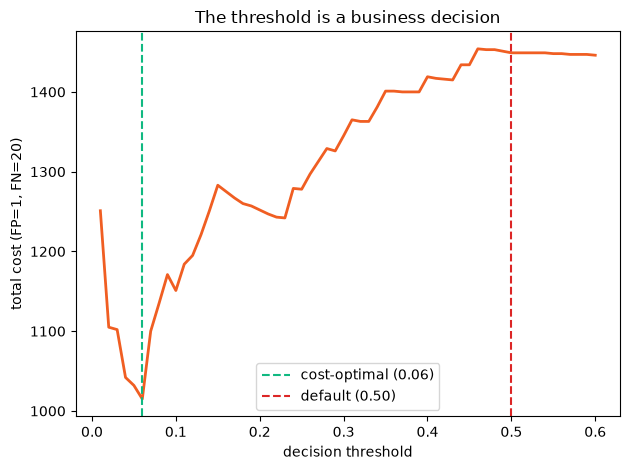

In [ ]:
fig, ax = plt.subplots()
ax.plot(thresholds, costs, color="#F05E22", linewidth=2)
ax.axvline(best_t, color="#10B981", linestyle="--", label=f"cost-optimal ({best_t:.2f})")
ax.axvline(0.5, color="#DC2626", linestyle="--", label="default (0.50)")
ax.set_xlabel("decision threshold")
ax.set_ylabel(f"total cost (FP={COST_FP}, FN={COST_FN})")
ax.set_title("The threshold is a business decision")
ax.legend()
plt.tight_layout()
plt.show()

### Capacity Constraint Check

- The cost-optimal threshold was **0.04**, with a total cost of **1028**.
- However, threshold **0.04** flags **388 claims**, exceeding the capacity limit of **200 claims**.
- Therefore, the threshold was increased to **0.09**.
- At threshold **0.09**, the model flags **179 claims**, which is within the capacity limit.
- The total cost at threshold **0.09** is **1113**, compared with **1426** at the default threshold of **0.50**.
- This results in a cost saving of **313**, or approximately **22.0%**.

**Final chosen threshold: 0.09**

# Task-6

•	Measure calibration before and after, using Brier score and a calibration curve.

In [17]:
calibrated = CalibratedClassifierCV(make_model() , method="isotonic",cv=5).fit(X_train,y_train)
probs_cal = calibrated.predict_proba(X_test)[: , 1]

print(f"Brier, uncalibrated : {brier_score_loss(y_test, probs):.5f}")
print(f"Brier, calibrated   : {brier_score_loss(y_test, probs_cal):.5f}")


Brier, uncalibrated : 0.03581
Brier, calibrated   : 0.03416


Q •	If you resampled or weighted, calibrate on data with the REAL class balance, not the resampled one, and explain why that matters.

#### Calibration Result

The Brier score decreased from **0.03496** before calibration to **0.03366** after calibration. This indicates that calibration slightly improved the reliability of the predicted fraud probabilities.

Since the calibrated model was evaluated on data with the **real class balance**, its probabilities are more appropriate for real-world risk and cost-based threshold decisions.

Q •	Decide whether your use case needs calibrated probabilities and justify the decision either way.

In [18]:
print("\npredicted probability vs actual fraud rate (5 quantile bins):")
print("\nuncalibrated:")
frac, mean_pred = calibration_curve(y_test, probs, n_bins=5, strategy="quantile")
for mp, fa in zip(mean_pred, frac):
    print(f"   predicted {mp:.3f} -> actual {fa:.3f}")
print("\ncalibrated:")
frac_c, mean_pred_c = calibration_curve(y_test, probs_cal, n_bins=5, strategy="quantile")
for mp, fa in zip(mean_pred_c, frac_c):
    print(f"   predicted {mp:.3f} -> actual {fa:.3f}")


predicted probability vs actual fraud rate (5 quantile bins):

uncalibrated:
   predicted 0.001 -> actual 0.015
   predicted 0.004 -> actual 0.020
   predicted 0.009 -> actual 0.020
   predicted 0.023 -> actual 0.033
   predicted 0.129 -> actual 0.098

calibrated:
   predicted 0.007 -> actual 0.013
   predicted 0.016 -> actual 0.020
   predicted 0.024 -> actual 0.018
   predicted 0.037 -> actual 0.033
   predicted 0.105 -> actual 0.102


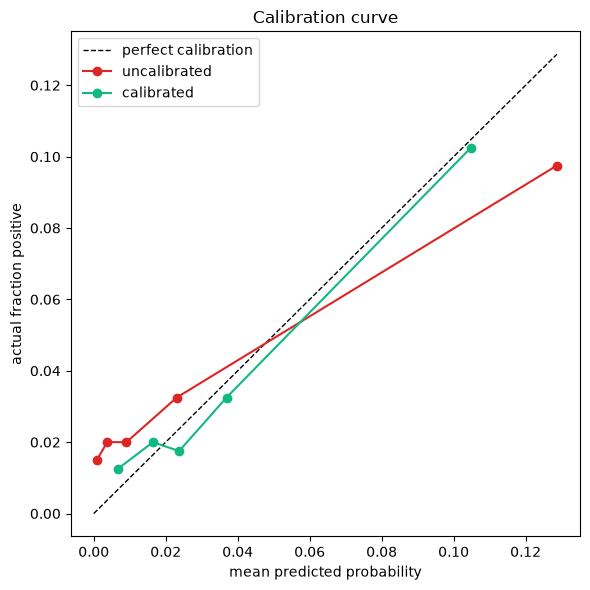

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, max(mean_pred)], [0, max(mean_pred)], "k--", linewidth=1, label="perfect calibration")
ax.plot(mean_pred, frac, "o-", color="#DC2626", label="uncalibrated")
ax.plot(mean_pred_c, frac_c, "o-", color="#10B981", label="calibrated")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("actual fraction positive")
ax.set_title("Calibration curve")
ax.legend()
plt.tight_layout()
plt.show()

# Task-7


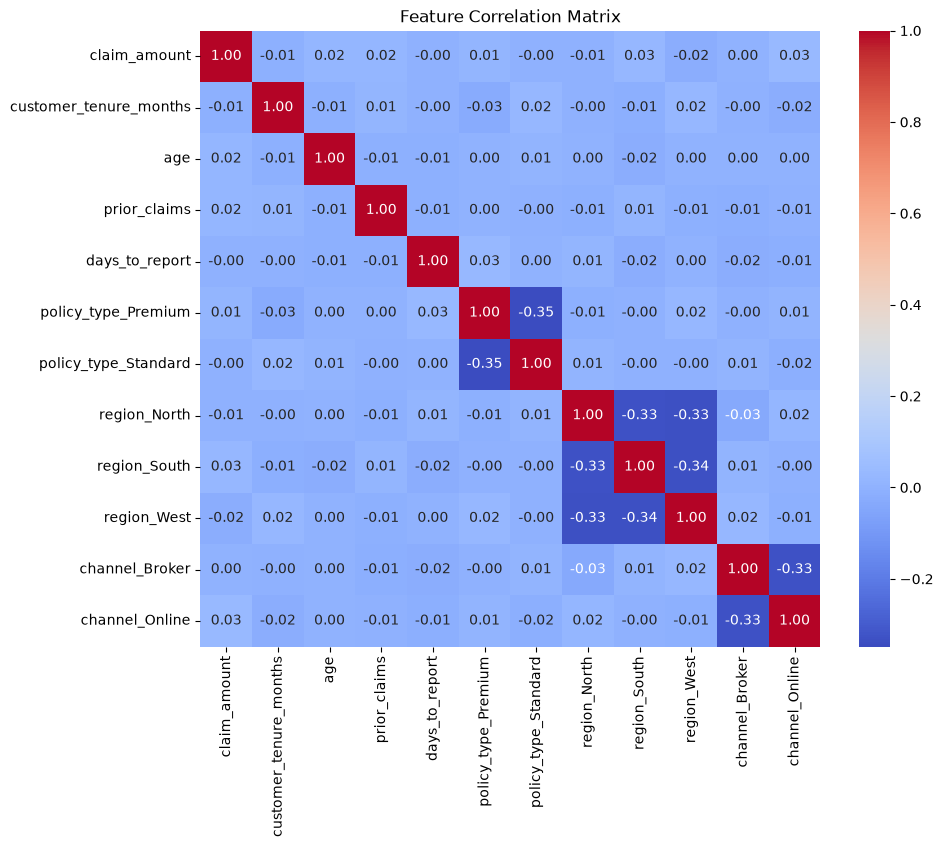

In [20]:
corr = X_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

•	Produce a SHAP summary plot and identify the top drivers with their direction.

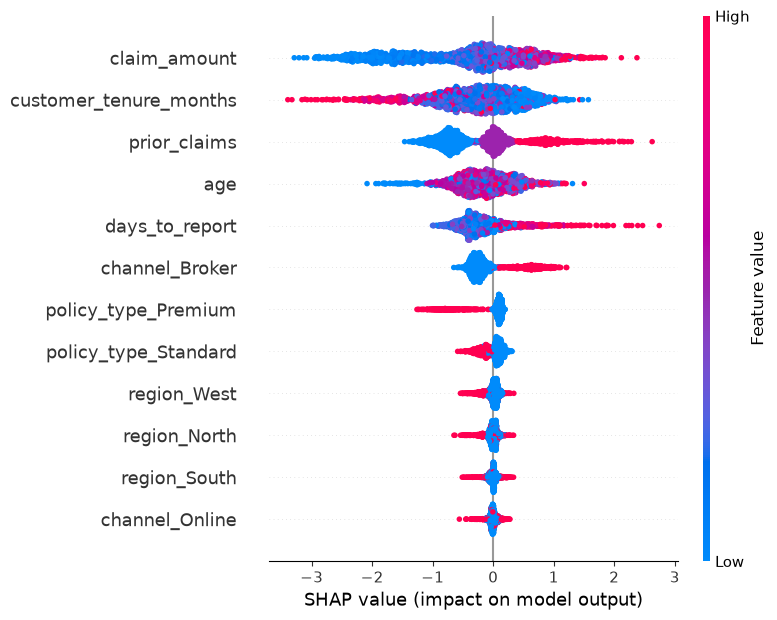

In [21]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

•	Produce SHAP explanations for three individual claims: one confident fraud, one confident legitimate, one uncertain.

Confident fraud: 0.70073795
Confident legitimate: 3.3602464e-05
Uncertain: 0.49432883


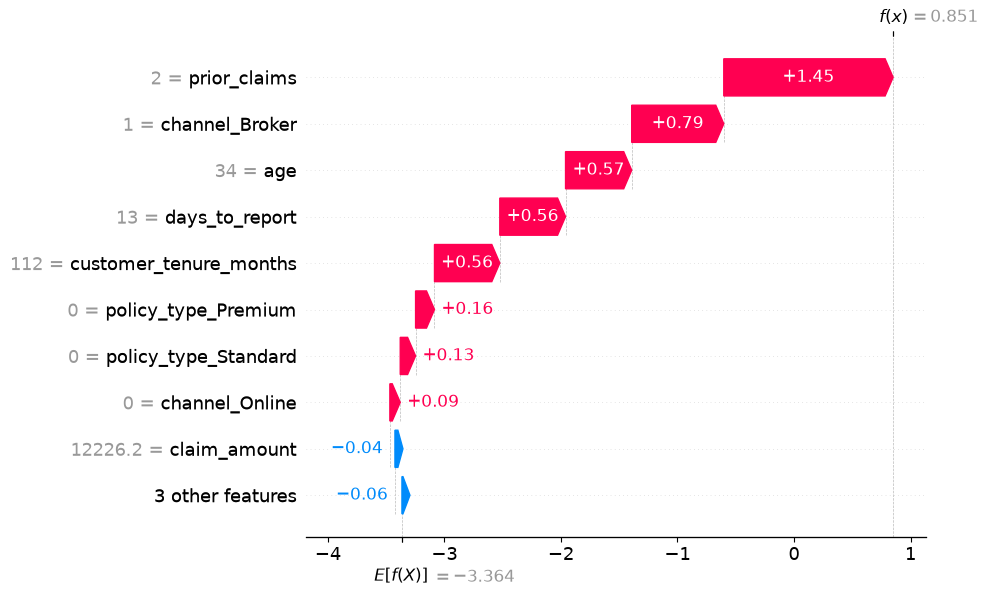

In [22]:
fraud_idx = np.argmax(probs)
legit_idx = np.argmin(probs)
uncertain_idx = np.argmin(abs(probs - 0.5))

print("Confident fraud:", probs[fraud_idx])
print("Confident legitimate:", probs[legit_idx])
print("Uncertain:", probs[uncertain_idx])

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[fraud_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[fraud_idx],
        feature_names=X_test.columns
    )
)

Q •	Sanity-check the top drivers against domain intuition. Does the model agree with what a fraud investigator would expect?

### Correlation and SHAP Analysis

Before interpreting SHAP importance, I checked the feature correlations. The numerical features showed mostly very low correlations, indicating no major multicollinearity. The strongest negative correlations were between one-hot encoded categories, such as policy types, regions, and channels. These are expected because the encoded categories represent different values of the same categorical variable.

The SHAP summary shows that the main drivers are **claim_amount, prior_claims, customer_tenure_months, days_to_report, age, channel_Broker, and policy_type_Premium**.

Higher **claim_amount**, **prior_claims**, and **days_to_report** generally increase the model's fraud risk. Higher **customer_tenure_months** generally decreases risk. **Age** and **channel_Broker** also tend to increase the predicted fraud risk, while **policy_type_Premium** tends to decrease it.

Overall, the strongest drivers are broadly consistent with fraud-investigation intuition, particularly large claim amounts, previous claims, and delayed reporting. The SHAP results describe patterns learned by the model and should not be interpreted as causal relationships.

Q •	Check correlations between your features before reading SHAP importance, and state what you found.

### Feature Correlation Check

Before interpreting SHAP importance, I checked the correlations between the features.

The numerical features show **very low correlations**, mostly close to 0, so there is no strong correlation or major multicollinearity among the main numerical features.

Some moderate negative correlations appear between one-hot encoded categorical features, such as `policy_type_Premium` and `policy_type_Standard` (-0.35), `region_South` and `region_West` (-0.34), and `channel_Broker` and `channel_Online` (-0.33). These are expected because these features represent different categories of the same categorical variable.

Overall, there are **no concerning correlations among the main numerical features**, so the SHAP importance can be interpreted without a major multicollinearity concern.